# 03 · RFM segmentation & cohort retention
**Business questions:** *Who are our best customers? When do new customers drop off?*

RFM scoring (see `sql/04_rfm.sql`): R and M are quintiles; **F uses business bins** (1 / 2 / 3–4 / 5–9 / 10+ orders) because ~27% of customers have exactly one order and quintiles would split identical customers arbitrarily. SQL and Python implementations are tested to agree customer-by-customer.

In [1]:
import sys, pandas as pd
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
from IPython.display import Image, display
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
T = ROOT / 'reports' / 'tables'; F = ROOT / 'reports' / 'figures'
def fig(name): display(Image(filename=str(F / f'{name}.png')))

In [2]:
pd.read_csv(T / 'sql_rfm_segment_summary.csv')

,rfm_segment,customers,pct_customers,net_revenue,pct_revenue,median_recency_days,avg_orders,median_revenue
0,Champions,802,0.137,"8,551,772.000",0.524,8.000,19.600,"4,061.000"
1,Loyal Customers,1040,0.178,"4,400,999.000",0.270,51.000,10.300,"2,694.000"
2,At Risk,650,0.111,"883,654.000",0.054,367.000,4.400,"1,060.000"
3,Hibernating,1626,0.279,"703,520.000",0.043,431.000,1.300,286.000
4,Potential Loyalists,720,0.123,"693,070.000",0.043,23.000,2.900,747.000
5,Cannot Lose Them,59,0.010,"458,054.000",0.028,303.000,18.100,"3,924.000"
6,Need Attention,281,0.048,"323,079.000",0.020,100.000,3.500,935.000
7,About to Sleep,424,0.073,"220,580.000",0.013,96.000,1.400,362.000
8,Promising,161,0.028,"53,452.000",0.003,38.000,1.000,225.000
9,New Customers,76,0.013,"32,713.000",0.002,11.000,1.000,286.000


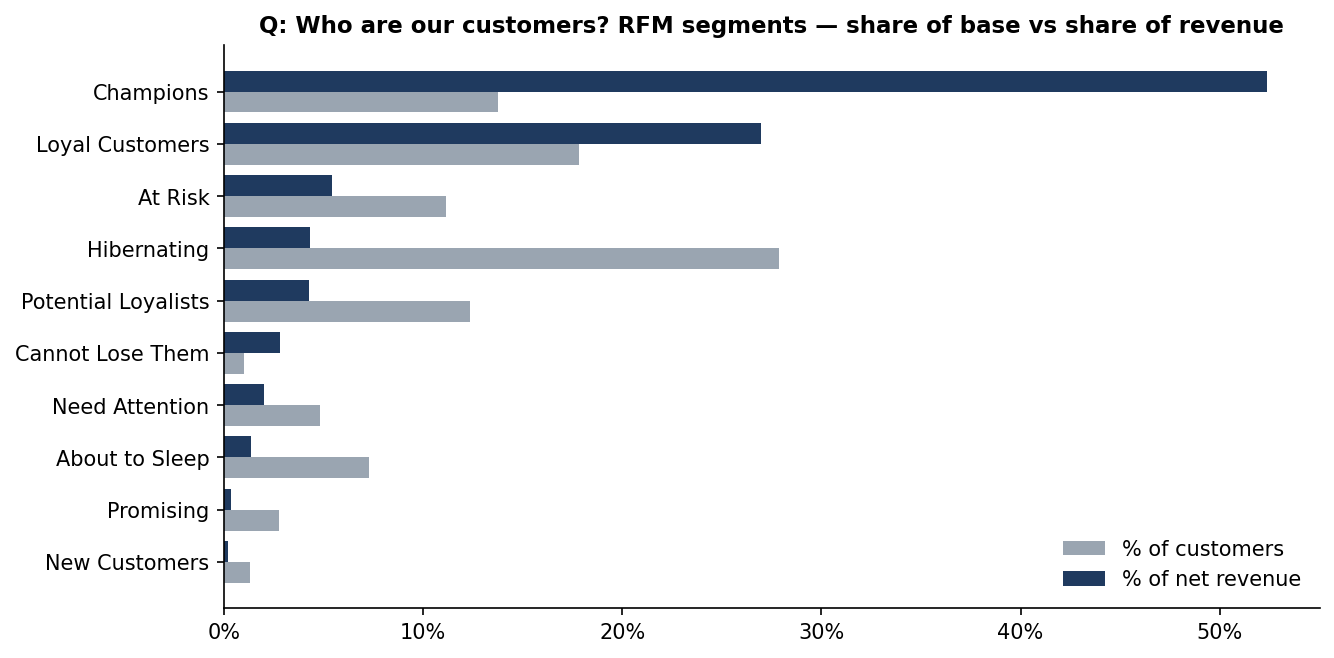

In [3]:
fig('07_rfm_segments')

**Read-out:** Champions (14% of customers) and Loyal Customers (18%) generate ~79% of net revenue. Hibernating customers are 28% of the base but 4% of revenue.

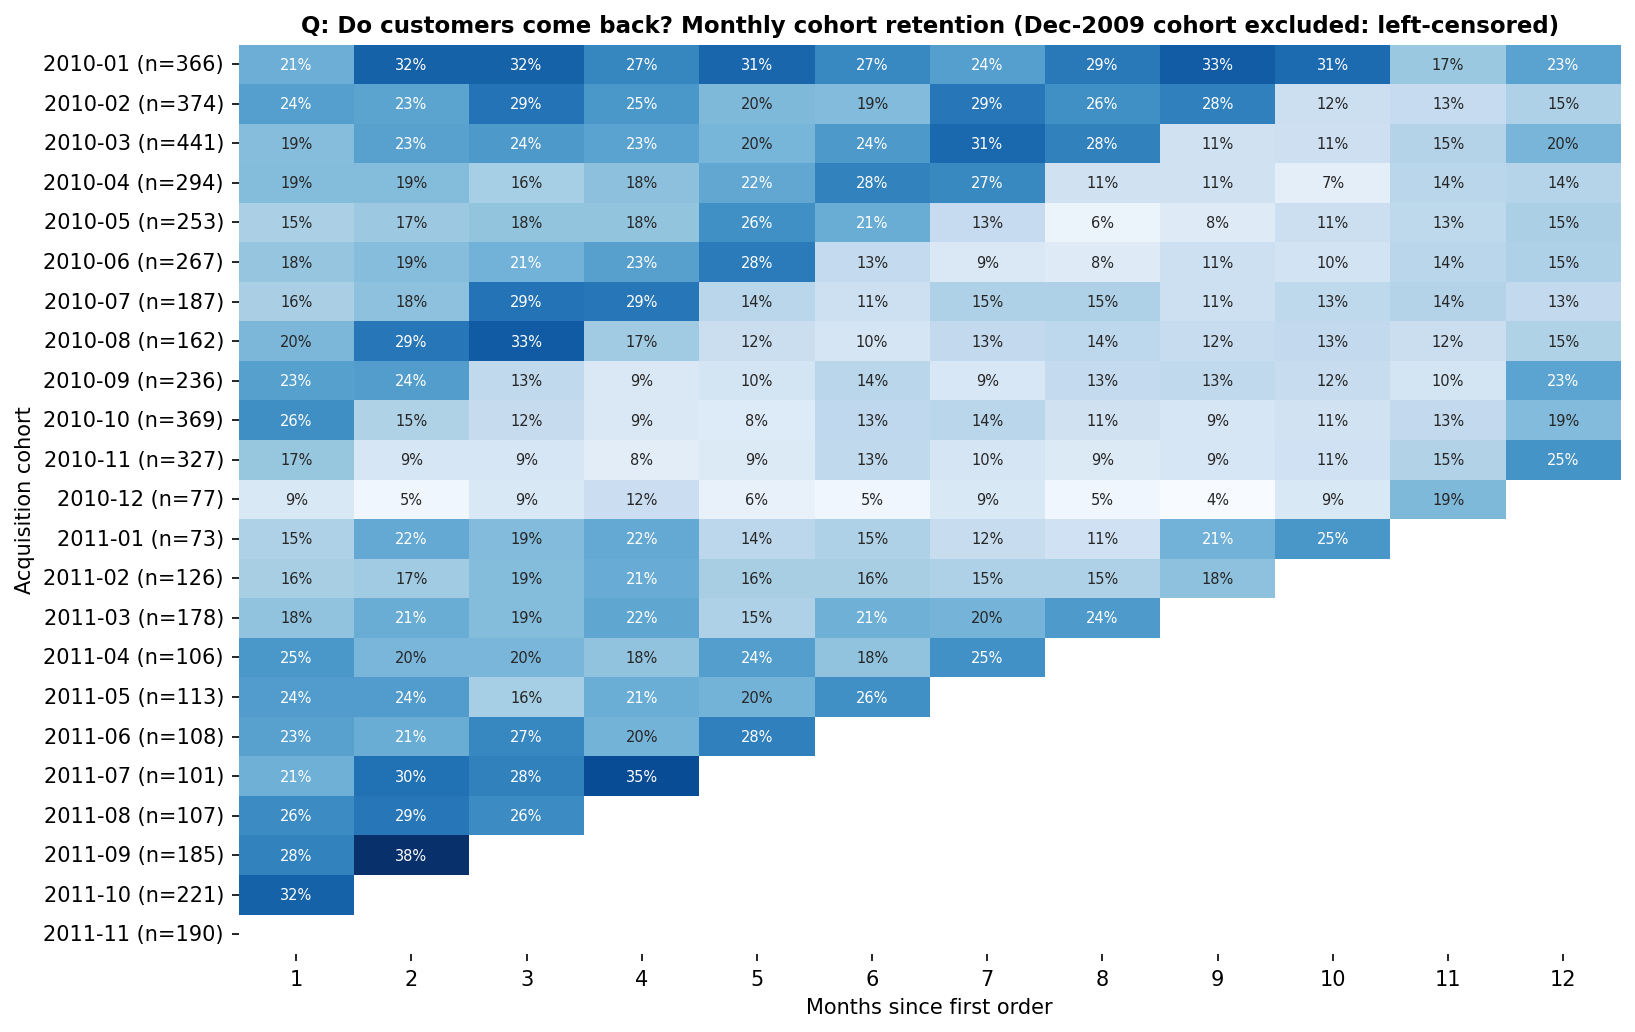

In [4]:
fig('04_cohort_retention_heatmap')

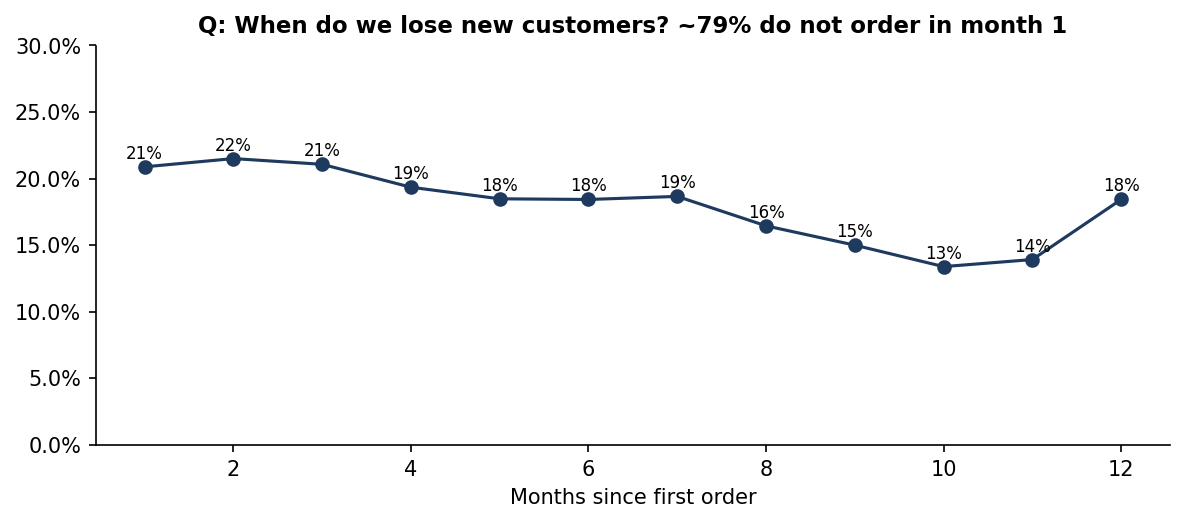

In [5]:
fig('05_average_retention_curve')

**Read-out and caveats**
* Only ~21% of new customers order again in the month after their first order.
* Retention follows the **calendar**, not customer age: diagonal bands of high retention line up with the Sep–Nov peak for every cohort.
* Cohorts acquired in the 2010 peak retain worse over the following six months (13% vs 22%), but those months are the quiet season and they return for the next peak at similar rates — so this is **seasonality, not lower-quality customers**. Two years of data cannot fully separate the two.
* The Dec-2009 cohort is excluded: it is left-censored (contains existing customers whose earlier history is missing). Early-2010 cohorts are partly affected too.

In [6]:
pd.read_csv(T / 'rfm_vs_management_segments.csv', index_col=0)

,1. Protect - Key Accounts,2. Rescue - High Value at Risk,3. Develop - Core Growth,4. Win Back - Core at Risk,5. Nurture - New Customers,6. Automate - Low Value Active,7. Deprioritise - Low Value Lapsing,8. Lapsed (>12m) - Win-back Pool
rfm_segment,,,,,,,,
About to Sleep,0,5,37,16,136,54,176,0
At Risk,0,4,16,26,0,53,212,339
Cannot Lose Them,0,9,0,11,0,3,15,21
Champions,440,0,262,0,28,72,0,0
Hibernating,0,4,10,27,0,14,347,1224
Loyal Customers,244,78,432,15,2,255,13,1
Need Attention,5,3,87,12,0,117,55,2
New Customers,0,0,0,0,75,0,0,1
Potential Loyalists,21,4,176,1,189,266,62,1


**Why RFM is not the final segmentation:** RFM is backward-looking. 72 'Champions' are low-spend frequent buyers, and 78 'Loyal Customers' are already drifting (Rescue segment). Management segments (notebook 06) combine current value with forward-looking risk.

## What should management do differently?
1. **Engineer the second order**: the biggest drop-off happens straight after the first purchase. A second-order programme for new customers within 60 days is the highest-leverage lifecycle intervention.
2. **Plan retention around the season**: re-engage the base before September, not after Christmas.
3. **Judge acquisition cohorts on a like-for-like season**, not on raw month-N retention.